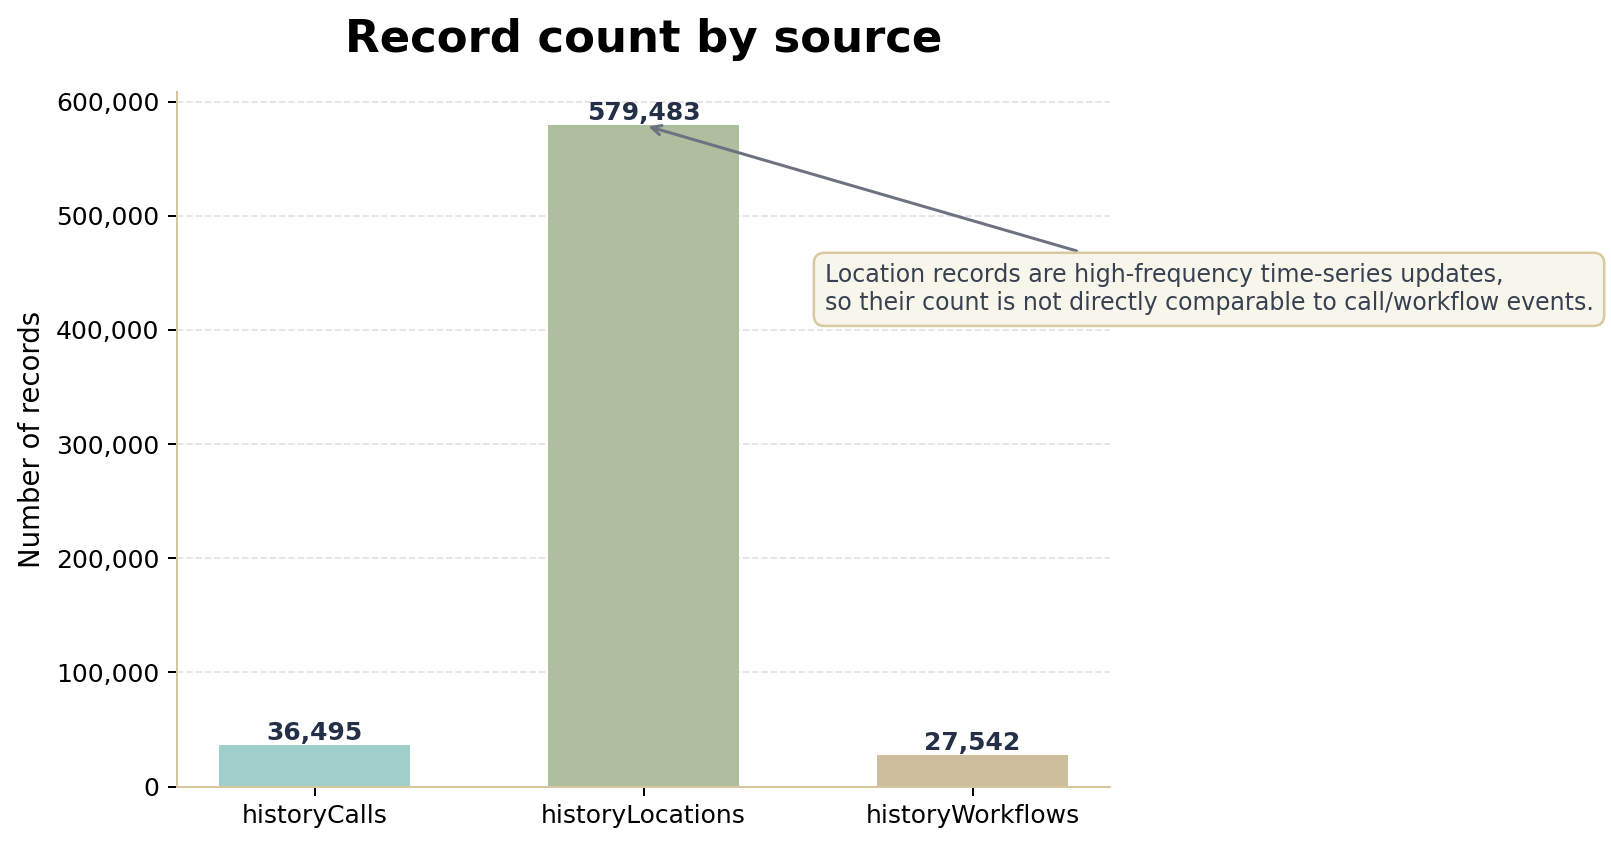

             source  records
0      historyCalls    36495
1  historyLocations   579483
2  historyWorkflows    27542
Saved to: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\record_count_by_source.png


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path(r"C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant")

DATASETS = {
    "historyCalls": ROOT / "data/historyCalls/03_processed/fact_history_calls_v3.csv",
    "historyLocations": ROOT / "data/historyLocations/processed/fact_history_locations_v1.csv",
    "historyWorkflows": ROOT / "data/historyWorkflows/processed/fact_history_workflows_v1.csv",
}

counts = {}
for name, path in DATASETS.items():
    # Fast CSV row count, excluding header
    with path.open("rb") as f:
        counts[name] = sum(1 for _ in f) - 1

df = pd.DataFrame({
    "source": list(counts.keys()),
    "records": list(counts.values()),
})

colors = {
    "historyCalls": "#9FCFCA",
    "historyLocations": "#AEBF9F",
    "historyWorkflows": "#CDBF9D",
}

plt.rcParams["font.family"] = "DejaVu Sans"

fig, ax = plt.subplots(figsize=(8.6, 4.8), dpi=180)
bars = ax.bar(
    df["source"],
    df["records"],
    color=[colors[s] for s in df["source"]],
    width=0.58,
)

ax.set_title("Record count by source", fontsize=18, weight="bold", pad=16)
ax.set_ylabel("Number of records", fontsize=11)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#D6C79E")
ax.spines["bottom"].set_color("#D6C79E")
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
ax.set_axisbelow(True)

for bar, value in zip(bars, df["records"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=10,
        weight="bold",
        color="#243047",
    )

# Important note for the slide
ax.annotate(
    "Location records are high-frequency time-series updates,\nso their count is not directly comparable to call/workflow events.",
    xy=(1, df.loc[df["source"] == "historyLocations", "records"].iloc[0]),
    xytext=(1.55, max(df["records"]) * 0.72),
    arrowprops=dict(arrowstyle="->", color="#6B7280", lw=1.2),
    fontsize=9.5,
    color="#374151",
    bbox=dict(boxstyle="round,pad=0.45", fc="#F8F5EA", ec="#D6C79E", alpha=0.95),
)

plt.tight_layout()
out = ROOT / "outputs/record_count_by_source.png"
out.parent.mkdir(exist_ok=True)
plt.savefig(out, bbox_inches="tight", facecolor="white")
plt.show()

print(df)
print(f"Saved to: {out}")

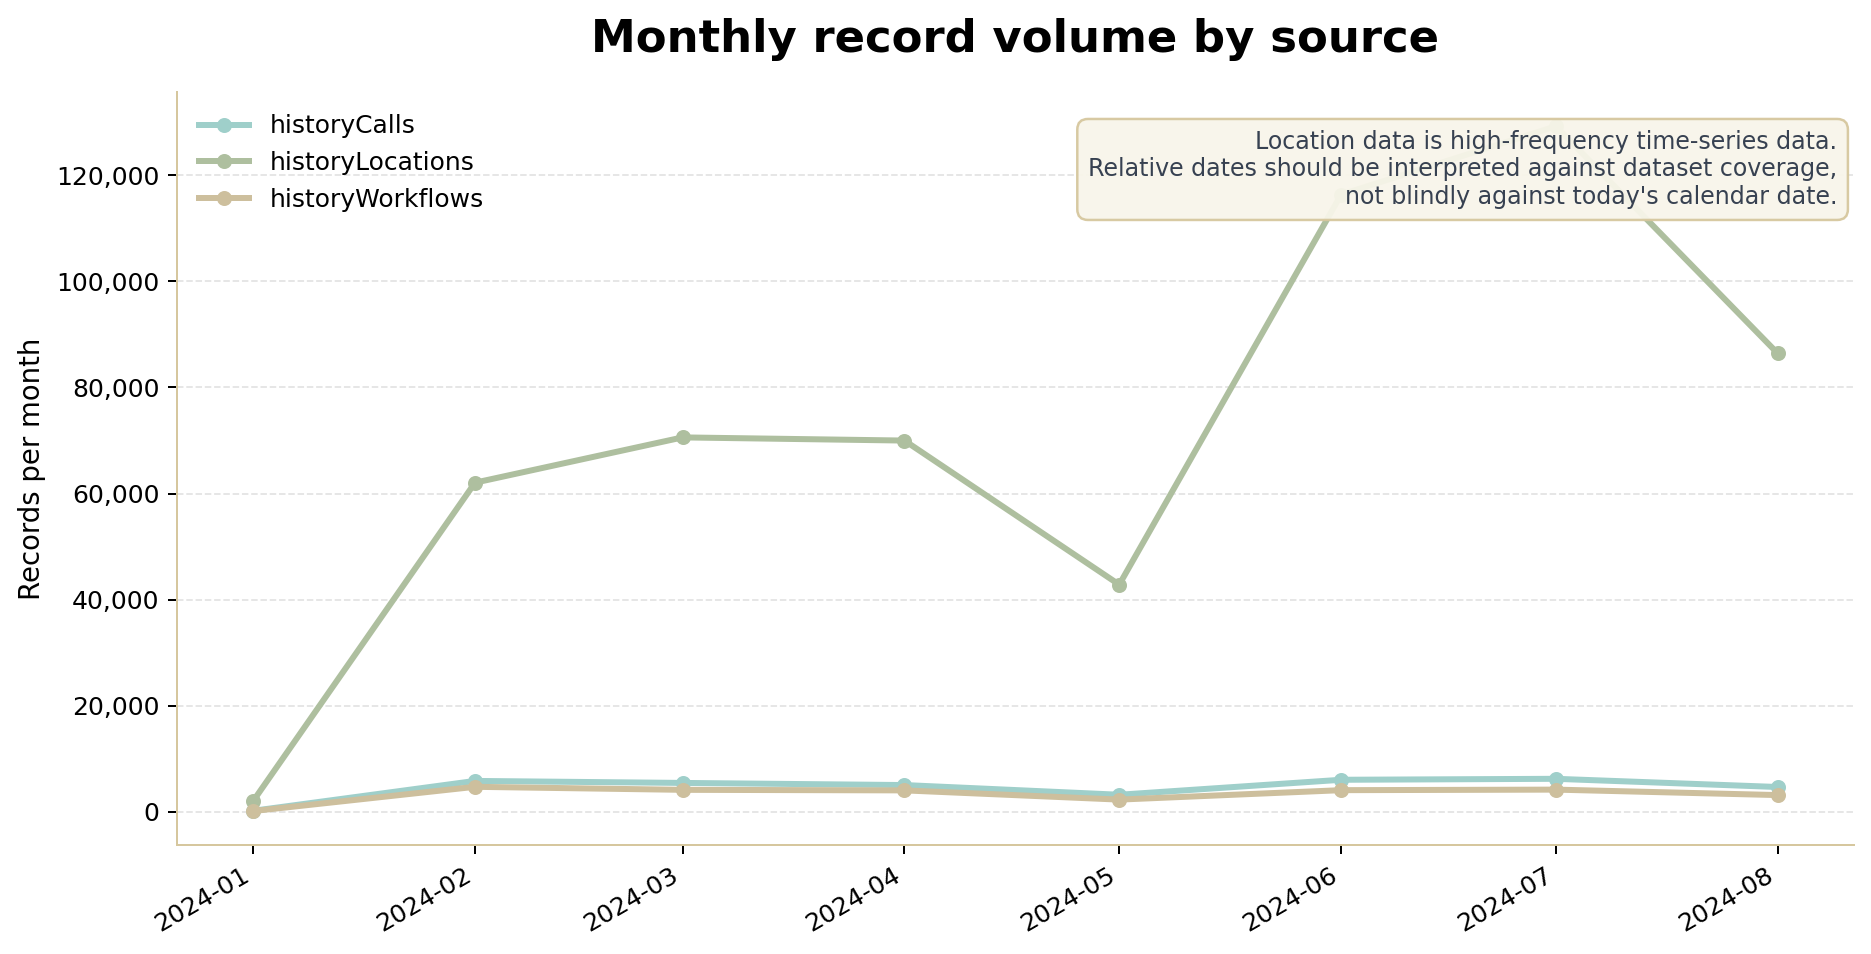

Coverage summary:
          source    date_field  records   earliest     latest
    historyCalls     call_date    36495 2024-01-31 2024-08-26
historyLocations     timestamp   579483 2024-01-31 2024-08-26
historyWorkflows workflow_date    27542 2024-01-31 2024-08-26

Saved to: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\monthly_record_volume_by_source.png


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path(r"C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant")

SOURCES = {
    "historyCalls": {
        "path": ROOT / "data/historyCalls/03_processed/fact_history_calls_v3.csv",
        "date_col": "call_date",
        "date_format": "mixed_dayfirst",
    },
    "historyLocations": {
        "path": ROOT / "data/historyLocations/processed/fact_history_locations_v1.csv",
        "date_col": "timestamp",
        "date_format": "timestamp",
    },
    "historyWorkflows": {
        "path": ROOT / "data/historyWorkflows/processed/fact_history_workflows_v1.csv",
        "date_col": "workflow_date",
        "date_format": "mixed_dayfirst",
    },
}

COLORS = {
    "historyCalls": "#9FCFCA",
    "historyLocations": "#AEBF9F",
    "historyWorkflows": "#CDBF9D",
}

def parse_dates(series: pd.Series, mode: str) -> pd.Series:
    if mode == "timestamp":
        return pd.to_datetime(series, errors="coerce")
    # call_date/workflow_date are dd/mm/YYYY in your samples
    return pd.to_datetime(series, errors="coerce", dayfirst=True)

monthly_frames = []
coverage_rows = []

for source, cfg in SOURCES.items():
    path = cfg["path"]
    date_col = cfg["date_col"]

    df = pd.read_csv(path, usecols=[date_col])
    dates = parse_dates(df[date_col], cfg["date_format"]).dropna()

    month_counts = (
        dates.dt.to_period("M")
        .value_counts()
        .sort_index()
        .rename("records")
        .reset_index()
    )
    month_counts.columns = ["month", "records"]
    month_counts["month"] = month_counts["month"].dt.to_timestamp()
    month_counts["source"] = source
    monthly_frames.append(month_counts)

    coverage_rows.append({
        "source": source,
        "date_field": date_col,
        "records": len(df),
        "earliest": dates.min().date() if not dates.empty else None,
        "latest": dates.max().date() if not dates.empty else None,
    })

monthly = pd.concat(monthly_frames, ignore_index=True)
coverage = pd.DataFrame(coverage_rows)

plt.rcParams["font.family"] = "DejaVu Sans"

fig, ax = plt.subplots(figsize=(10.5, 5.4), dpi=180)

for source, group in monthly.groupby("source"):
    ax.plot(
        group["month"],
        group["records"],
        marker="o",
        linewidth=2.4,
        markersize=5,
        label=source,
        color=COLORS[source],
    )

ax.set_title("Monthly record volume by source", fontsize=18, weight="bold", pad=16)
ax.set_ylabel("Records per month", fontsize=11)
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#D6C79E")
ax.spines["bottom"].set_color("#D6C79E")
ax.legend(frameon=False, loc="upper left")

# Slide explanation note
note = (
    "Location data is high-frequency time-series data.\n"
    "Relative dates should be interpreted against dataset coverage,\n"
    "not blindly against today's calendar date."
)
ax.text(
    0.99,
    0.95,
    note,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9.5,
    color="#374151",
    bbox=dict(boxstyle="round,pad=0.45", fc="#F8F5EA", ec="#D6C79E", alpha=0.95),
)

fig.autofmt_xdate(rotation=30)
plt.tight_layout()

out = ROOT / "outputs/monthly_record_volume_by_source.png"
out.parent.mkdir(exist_ok=True)
plt.savefig(out, bbox_inches="tight", facecolor="white")
plt.show()

print("Coverage summary:")
print(coverage.to_string(index=False))
print(f"\nSaved to: {out}")

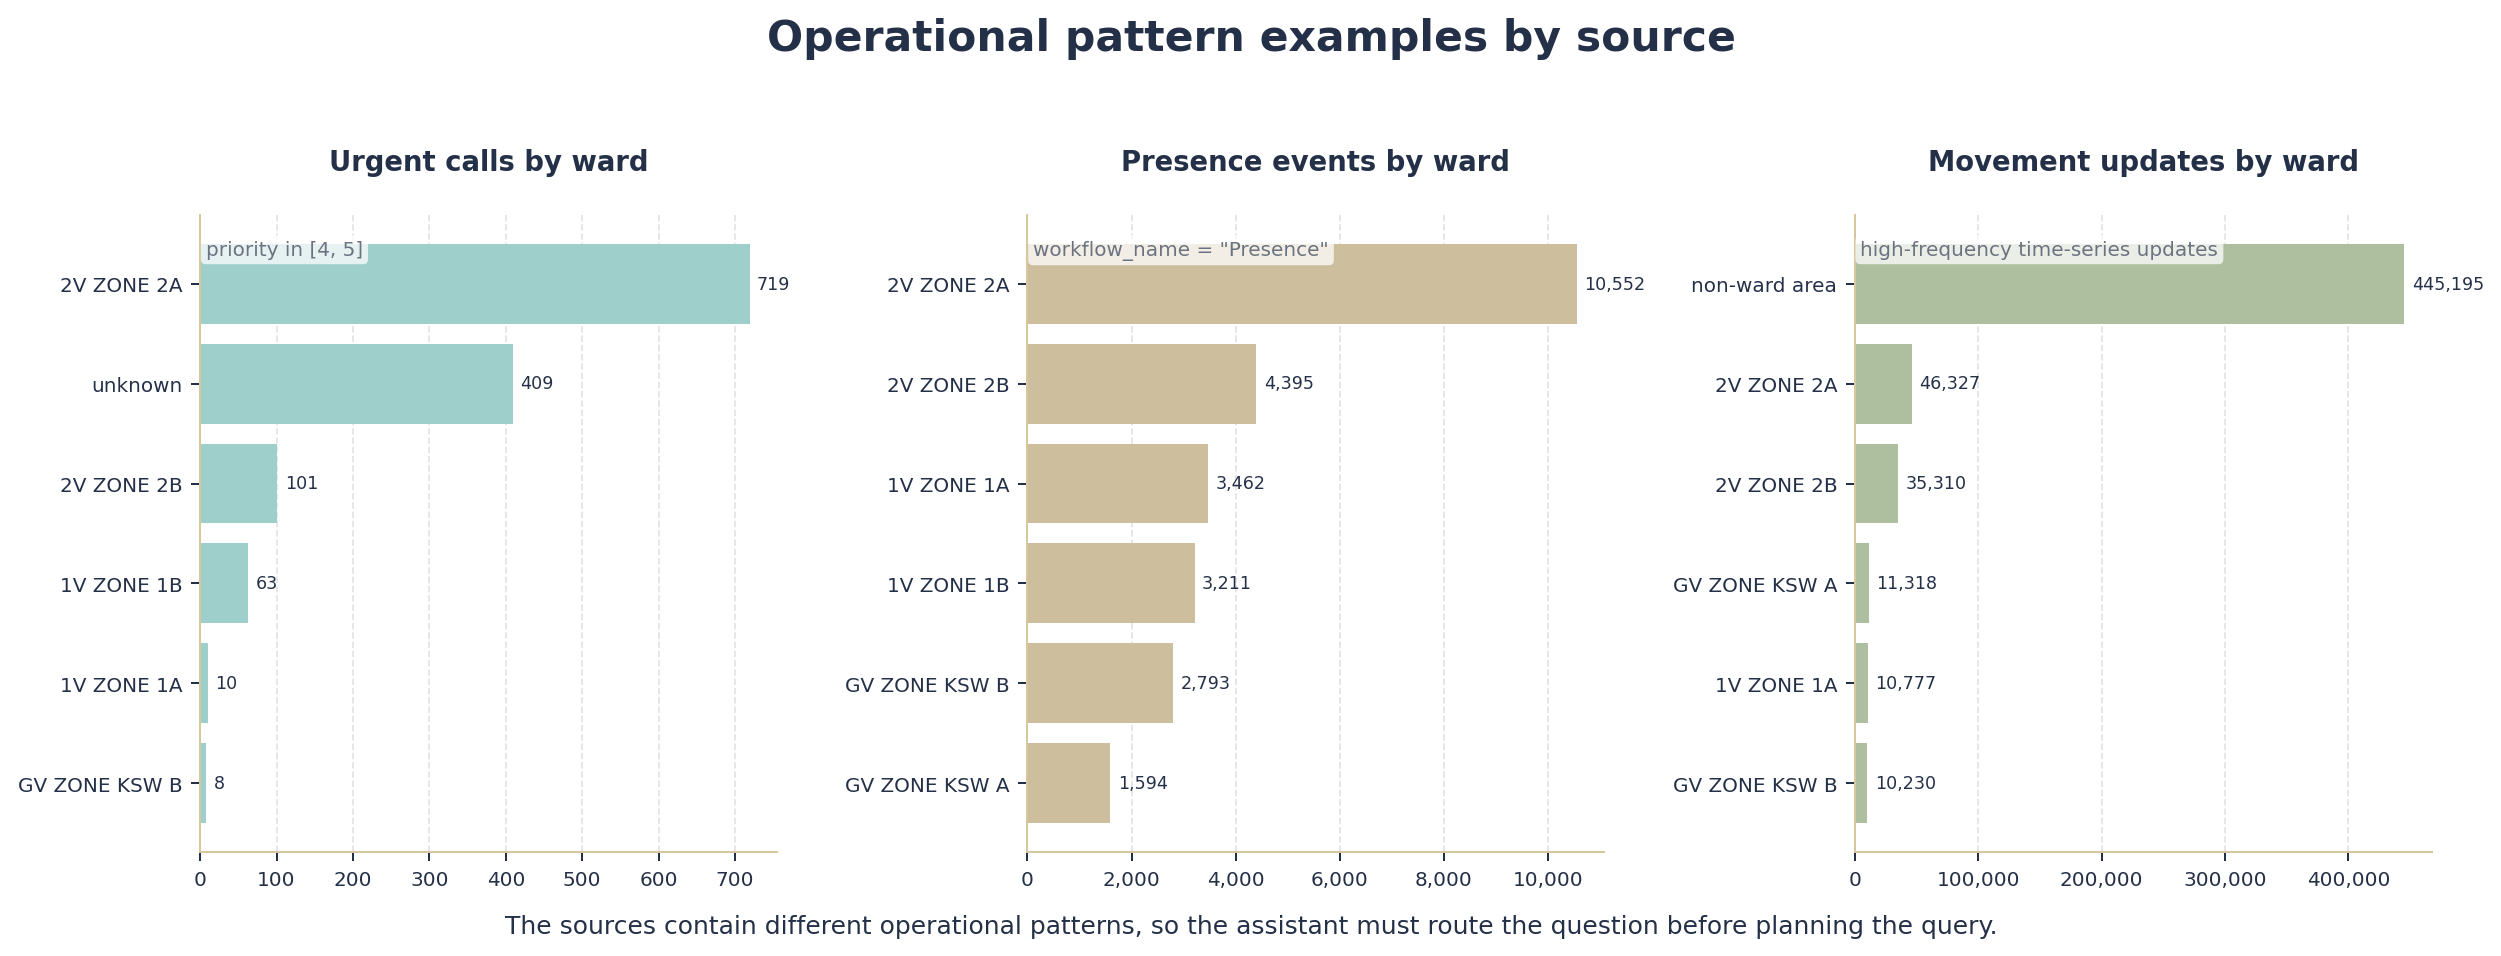

Saved combined plot to: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\operational_pattern_examples_by_source.png
Saved: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\calls_urgent_by_ward.png
Saved: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\workflows_presence_by_ward.png
Saved: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\locations_movement_by_ward.png


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path(r"C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

PATHS = {
    "calls": ROOT / "data/historyCalls/03_processed/fact_history_calls_v3.csv",
    "locations": ROOT / "data/historyLocations/processed/fact_history_locations_v1.csv",
    "workflows": ROOT / "data/historyWorkflows/processed/fact_history_workflows_v1.csv",
}

COLORS = {
    "calls": "#9FCFCA",
    "workflows": "#CDBF9D",
    "locations": "#AEBF9F",
}

TEXT = "#243047"
GRID = "#D6C79E"

plt.rcParams["font.family"] = "DejaVu Sans"


def top_counts(df, field, n=6):
    s = (
        df[field]
        .fillna("unknown")
        .replace("", "unknown")
        .value_counts()
        .head(n)
        .sort_values()
    )
    return s


def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.35)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.tick_params(axis="both", labelsize=8, colors=TEXT)


def add_bar_labels(ax):
    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[f"{int(v):,}" for v in container.datavalues],
            padding=3,
            fontsize=7,
            color=TEXT,
        )


# 1. Calls: urgent calls by ward
calls = pd.read_csv(PATHS["calls"], usecols=["priority", "ward_name"])
urgent_calls = calls[calls["priority"].isin([4, 5])]
urgent_by_ward = top_counts(urgent_calls, "ward_name", n=6)

# 2. Workflows: presence events by ward
workflows = pd.read_csv(PATHS["workflows"], usecols=["workflow_name", "ward_name"])
presence = workflows[workflows["workflow_name"].fillna("").eq("Presence")]
presence_by_ward = top_counts(presence, "ward_name", n=6)

# 3. Locations: movement updates by ward
locations = pd.read_csv(PATHS["locations"], usecols=["movement_status", "ward"])
moved = locations[locations["movement_status"].fillna("").eq("moved")]
movement_by_ward = top_counts(moved, "ward", n=6)


# Combined figure for your slide
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), dpi=180)

plots = [
    (
        axes[0],
        urgent_by_ward,
        "Calls",
        "Urgent calls by ward",
        COLORS["calls"],
        "priority in [4, 5]",
    ),
    (
        axes[1],
        presence_by_ward,
        "Workflows",
        "Presence events by ward",
        COLORS["workflows"],
        'workflow_name = "Presence"',
    ),
    (
        axes[2],
        movement_by_ward,
        "Locations",
        "Movement updates by ward",
        COLORS["locations"],
        "high-frequency time-series updates",
    ),
]

for ax, series, source_label, title, color, subtitle in plots:
    ax.barh(series.index.astype(str), series.values, color=color)
    ax.set_title(title, fontsize=11, weight="bold", color=TEXT, pad=18)

    # Put subtitle as a small label inside the plot area, below the title.
    ax.text(
        0.01,
        0.96,
        subtitle,
        transform=ax.transAxes,
        fontsize=8,
        color="#6B7280",
        ha="left",
        va="top",
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec="none",
            alpha=0.75,
        ),
    )

    style_axis(ax)
    add_bar_labels(ax)

fig.suptitle(
    "Operational pattern examples by source",
    fontsize=17,
    weight="bold",
    color=TEXT,
    y=1.04,
)

fig.text(
    0.5,
    -0.02,
    "The sources contain different operational patterns, so the assistant must route the question before planning the query.",
    ha="center",
    fontsize=10,
    color=TEXT,
)

plt.tight_layout()
combined_out = OUT / "operational_pattern_examples_by_source.png"
plt.savefig(combined_out, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Saved combined plot to: {combined_out}")


# Optional: save separate plots too
separate_specs = [
    ("calls_urgent_by_ward.png", urgent_by_ward, "Urgent calls by ward", COLORS["calls"]),
    ("workflows_presence_by_ward.png", presence_by_ward, "Presence events by ward", COLORS["workflows"]),
    ("locations_movement_by_ward.png", movement_by_ward, "Movement updates by ward", COLORS["locations"]),
]

for filename, series, title, color in separate_specs:
    fig, ax = plt.subplots(figsize=(6.2, 4.2), dpi=180)
    ax.barh(series.index.astype(str), series.values, color=color)
    ax.set_title(title, fontsize=15, weight="bold", color=TEXT, pad=12)
    style_axis(ax)
    add_bar_labels(ax)
    plt.tight_layout()
    out = OUT / filename
    plt.savefig(out, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"Saved: {out}")

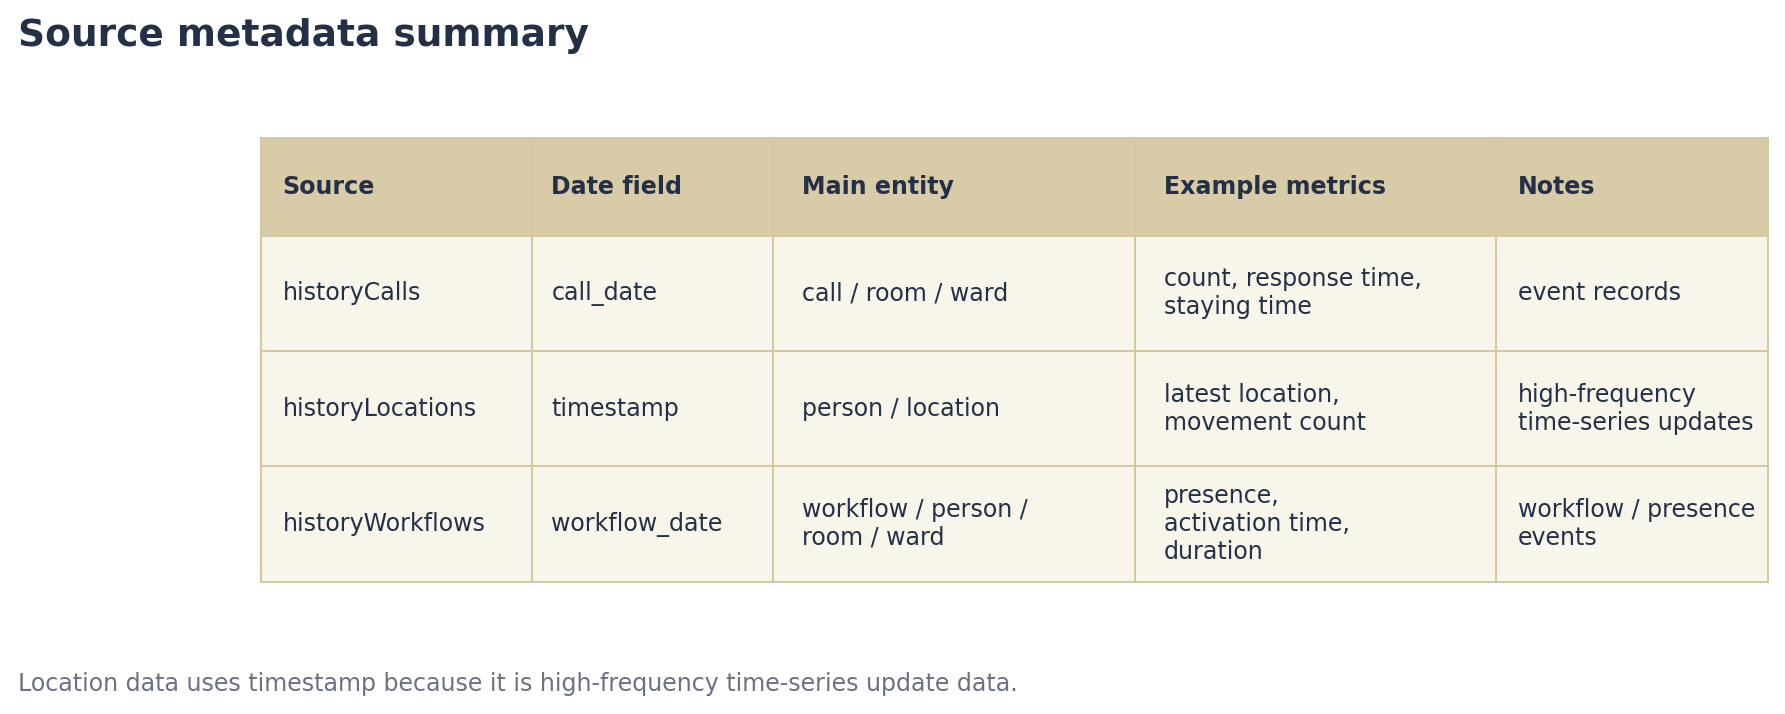

Saved to: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\source_metadata_summary.png


In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

rows = [
    {
        "Source": "historyCalls",
        "Date field": "call_date",
        "Main entity": "call / room / ward",
        "Example metrics": "count, response time,\nstaying time",
        "Notes": "event records",
    },
    {
        "Source": "historyLocations",
        "Date field": "timestamp",
        "Main entity": "person / location",
        "Example metrics": "latest location,\nmovement count",
        "Notes": "high-frequency\ntime-series updates",
    },
    {
        "Source": "historyWorkflows",
        "Date field": "workflow_date",
        "Main entity": "workflow / person /\nroom / ward",
        "Example metrics": "presence,\nactivation time,\nduration",
        "Notes": "workflow / presence\nevents",
    },
]

df = pd.DataFrame(rows)

TEXT = "#243047"
HEADER_BG = "#D8CBA7"
ROW_BG = "#F8F5EA"
EDGE = "#D6C79E"

plt.rcParams["font.family"] = "DejaVu Sans"

fig, ax = plt.subplots(figsize=(10.8, 3.2), dpi=180)
ax.axis("off")

table = ax.table(
    cellText=df.values,
    colLabels=df.columns,
    cellLoc="left",
    colLoc="left",
    loc="center",
    bbox=[0, 0, 1, 1],
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

# Column widths should sum roughly to 1.0
col_widths = [0.18, 0.16, 0.24, 0.24, 0.18]

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor(EDGE)
    cell.set_linewidth(0.8)
    cell.PAD = 0.08

    if col < len(col_widths):
        cell.set_width(col_widths[col])

    if row == 0:
        cell.set_facecolor(HEADER_BG)
        cell.set_text_props(weight="bold", color=TEXT)
        cell.set_height(0.22)
    else:
        cell.set_facecolor(ROW_BG)
        cell.set_text_props(color=TEXT)
        cell.set_height(0.26)

# Title
fig.text(
    0.0,
    1.04,
    "Source metadata summary",
    fontsize=15,
    weight="bold",
    color=TEXT,
    ha="left",
)

fig.text(
    0.0,
    -0.08,
    "Location data uses timestamp because it is high-frequency time-series update data.",
    fontsize=9.5,
    color="#6B7280",
    ha="left",
)

out = OUT / "source_metadata_summary.png"
plt.savefig(out, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Saved to: {out}")

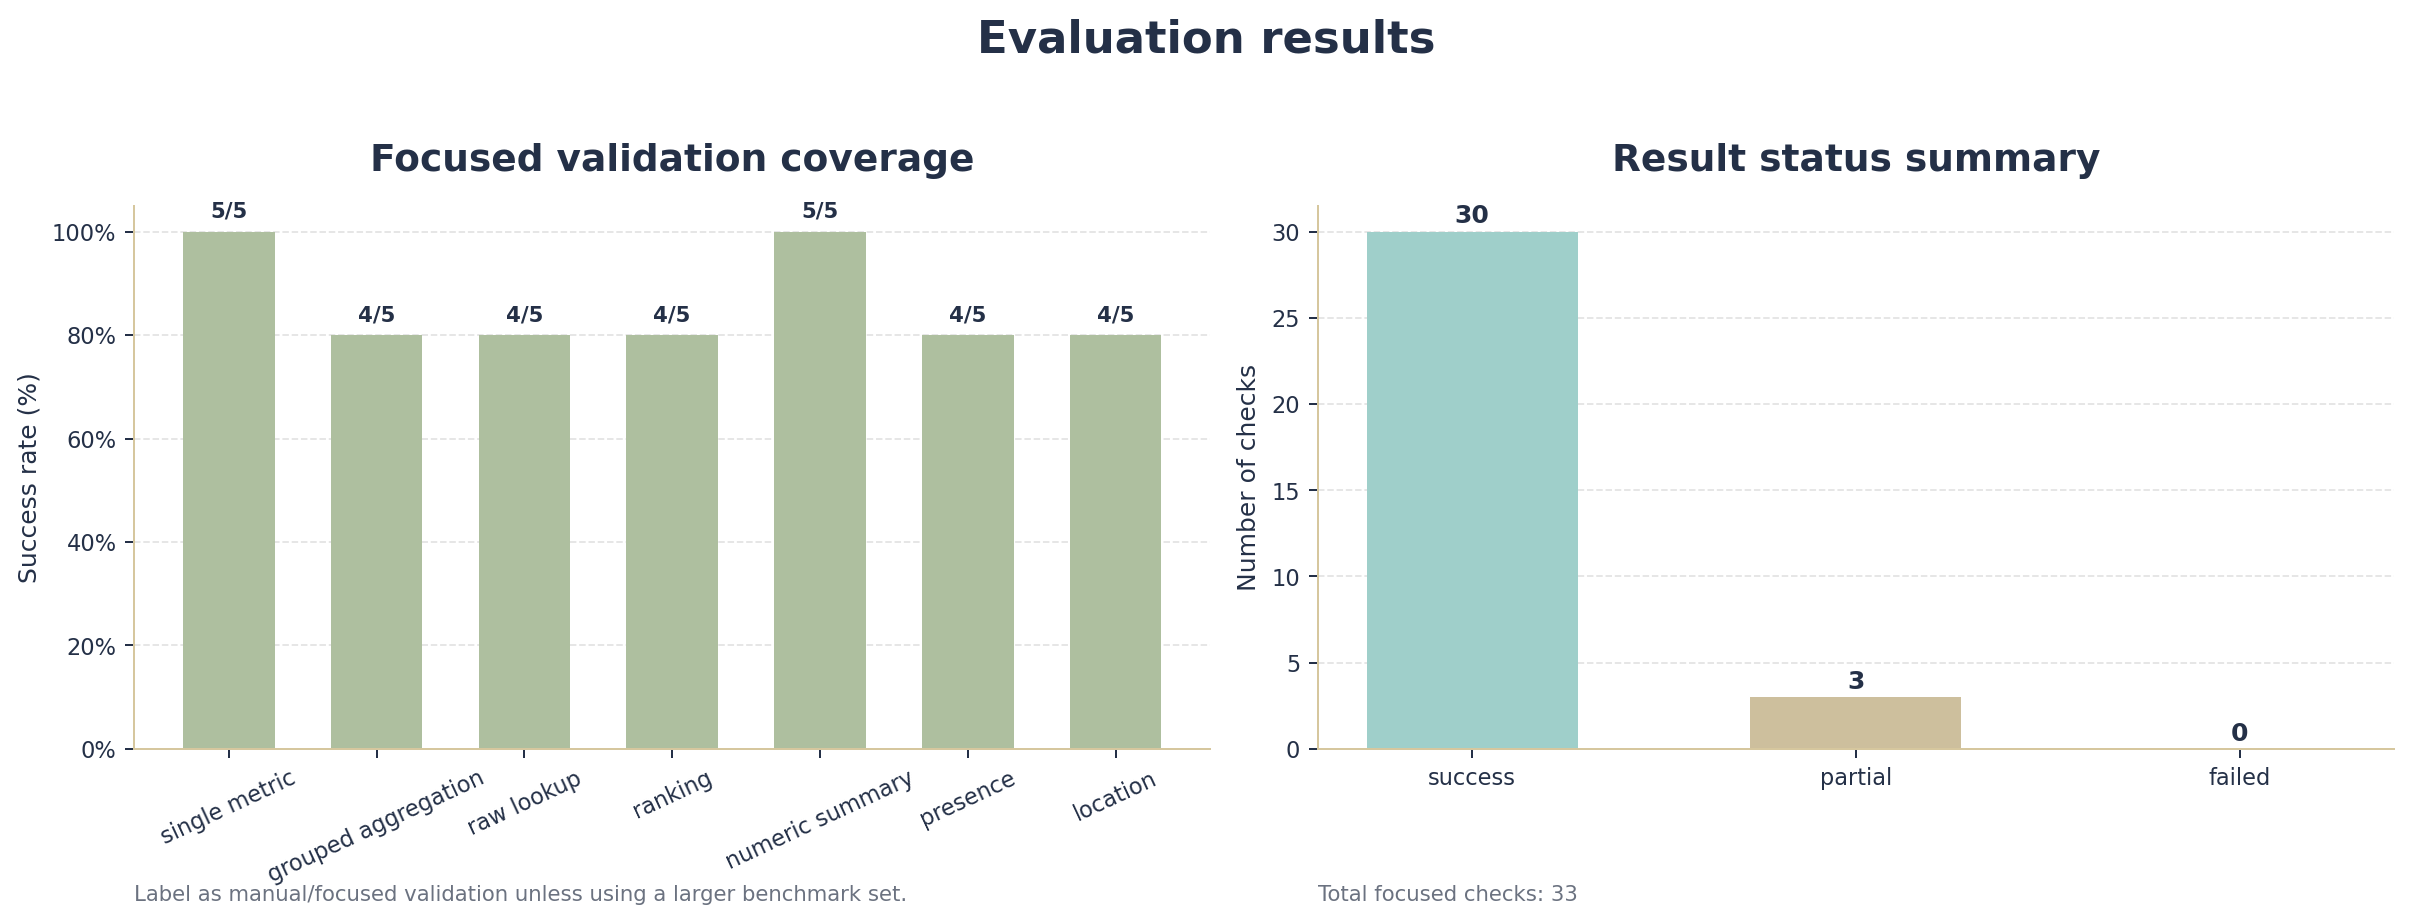

            capability  total  success  partial  failed  success_rate
0        single metric      5        5        0       0         100.0
1  grouped aggregation      5        4        0       0          80.0
2           raw lookup      5        4        0       0          80.0
3              ranking      5        4        1       0          80.0
4      numeric summary      5        5        0       0         100.0
5             presence      5        4        1       0          80.0
6             location      5        4        1       0          80.0
    status  count
0  success     30
1  partial      3
2   failed      0
Saved to: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\evaluation_results_focused_validation.png


In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path(r"C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

# Edit these numbers with your real focused/manual validation results.
# total = how many test questions you checked for that capability
# success / partial / failed should sum to total
results = [
    {
        "capability": "single metric",
        "total": 5,
        "success": 5,
        "partial": 0,
        "failed": 0,
    },
    {
        "capability": "grouped aggregation",
        "total": 5,
        "success": 4,
        "partial": 0,
        "failed": 0,
    },
    {
        "capability": "raw lookup",
        "total": 5,
        "success": 4,
        "partial": 0,
        "failed": 0,
    },
    {
        "capability": "ranking",
        "total": 5,
        "success": 4,
        "partial": 1,
        "failed": 0,
    },
    {
        "capability": "numeric summary",
        "total": 5,
        "success": 5,
        "partial": 0,
        "failed": 0,
    },
    {
        "capability": "presence",
        "total": 5,
        "success": 4,
        "partial": 1,
        "failed": 0,
    },
    {
        "capability": "location",
        "total": 5,
        "success": 4,
        "partial": 1,
        "failed": 0,
    },
]

df = pd.DataFrame(results)
df["success_rate"] = df["success"] / df["total"] * 100

status_totals = pd.DataFrame({
    "status": ["success", "partial", "failed"],
    "count": [df["success"].sum(), df["partial"].sum(), df["failed"].sum()],
})

TEXT = "#243047"
GRID = "#D6C79E"
SUCCESS = "#9FCFCA"
PARTIAL = "#CDBF9D"
FAILED = "#D98B8B"
BAR = "#AEBF9F"

plt.rcParams["font.family"] = "DejaVu Sans"


def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(axis="both", labelsize=9, colors=TEXT)
    ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180)

# Left plot: success rate by capability
ax = axes[0]
bars = ax.bar(
    df["capability"],
    df["success_rate"],
    color=BAR,
    width=0.62,
)
ax.set_title("Focused validation coverage", fontsize=15, weight="bold", color=TEXT, pad=14)
ax.set_ylabel("Success rate (%)", fontsize=10, color=TEXT)
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
style_axis(ax)
ax.tick_params(axis="x", rotation=25)

for bar, rate, success, total in zip(bars, df["success_rate"], df["success"], df["total"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 2,
        f"{success}/{total}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        weight="bold",
        color=TEXT,
    )

ax.text(
    0.0,
    -0.28,
    "Label as manual/focused validation unless using a larger benchmark set.",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#6B7280",
    ha="left",
)

# Right plot: status totals
ax = axes[1]
status_colors = [SUCCESS, PARTIAL, FAILED]
bars = ax.bar(
    status_totals["status"],
    status_totals["count"],
    color=status_colors,
    width=0.55,
)
ax.set_title("Result status summary", fontsize=15, weight="bold", color=TEXT, pad=14)
ax.set_ylabel("Number of checks", fontsize=10, color=TEXT)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
style_axis(ax)

for bar, value in zip(bars, status_totals["count"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{int(value)}",
        ha="center",
        va="bottom",
        fontsize=10,
        weight="bold",
        color=TEXT,
    )

total_checks = int(status_totals["count"].sum())
ax.text(
    0.0,
    -0.28,
    f"Total focused checks: {total_checks}",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#6B7280",
    ha="left",
)

fig.suptitle(
    "Evaluation results",
    fontsize=18,
    weight="bold",
    color=TEXT,
    y=1.03,
)

plt.tight_layout()

out = OUT / "evaluation_results_focused_validation.png"
plt.savefig(out, bbox_inches="tight", facecolor="white")
plt.show()

print(df)
print(status_totals)
print(f"Saved to: {out}")

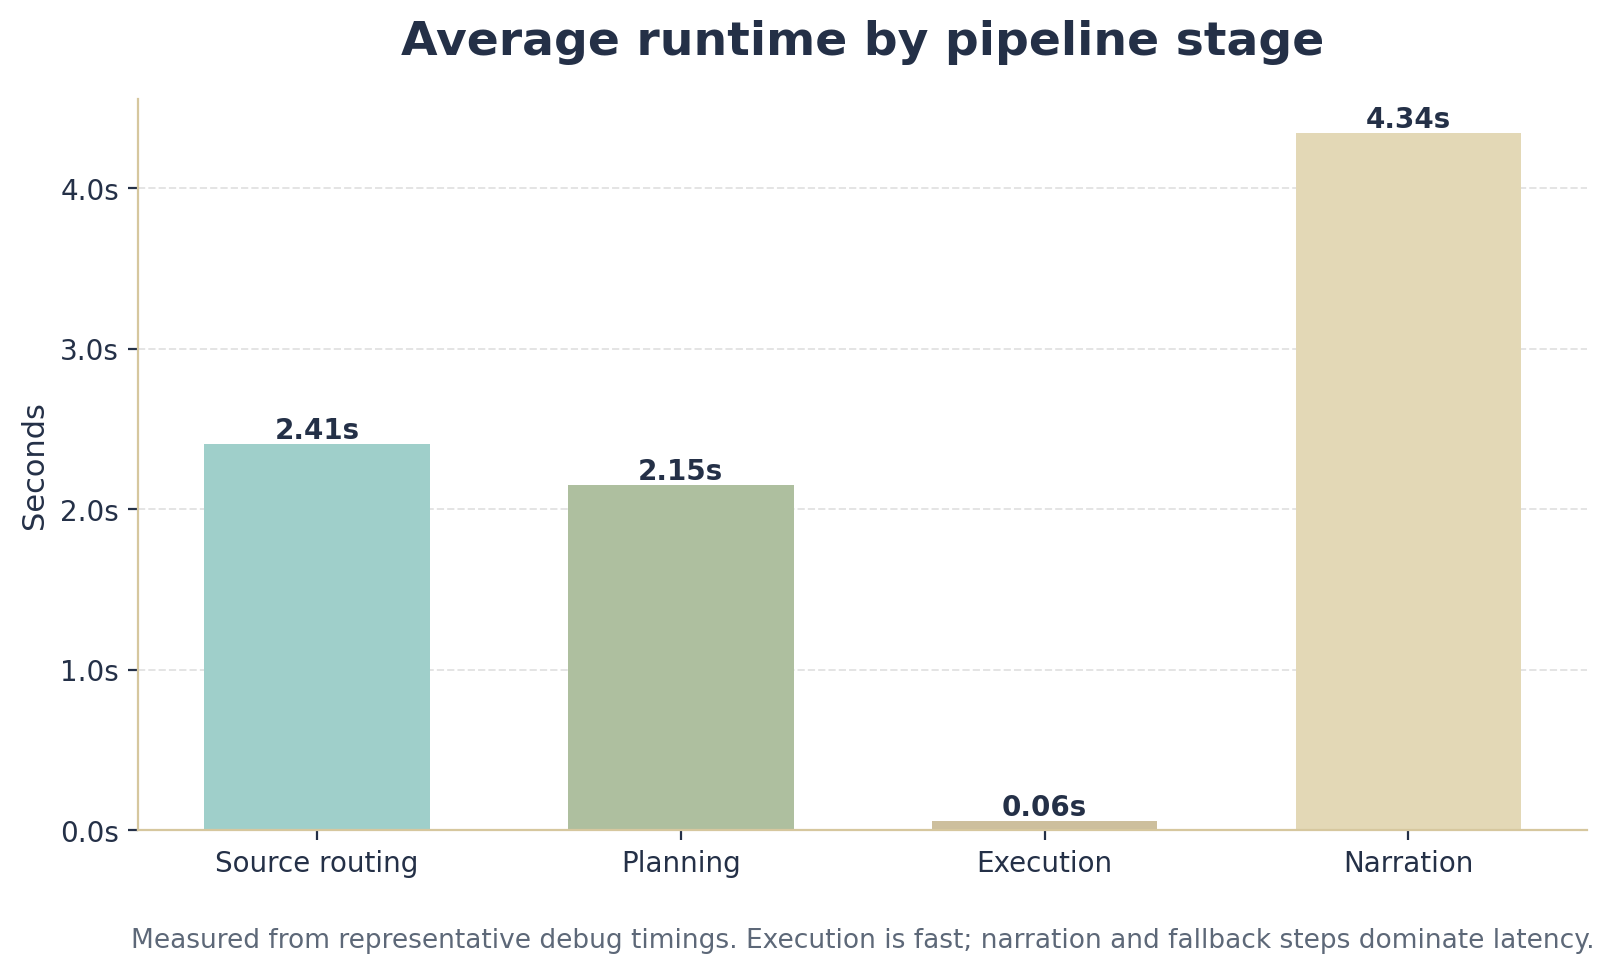

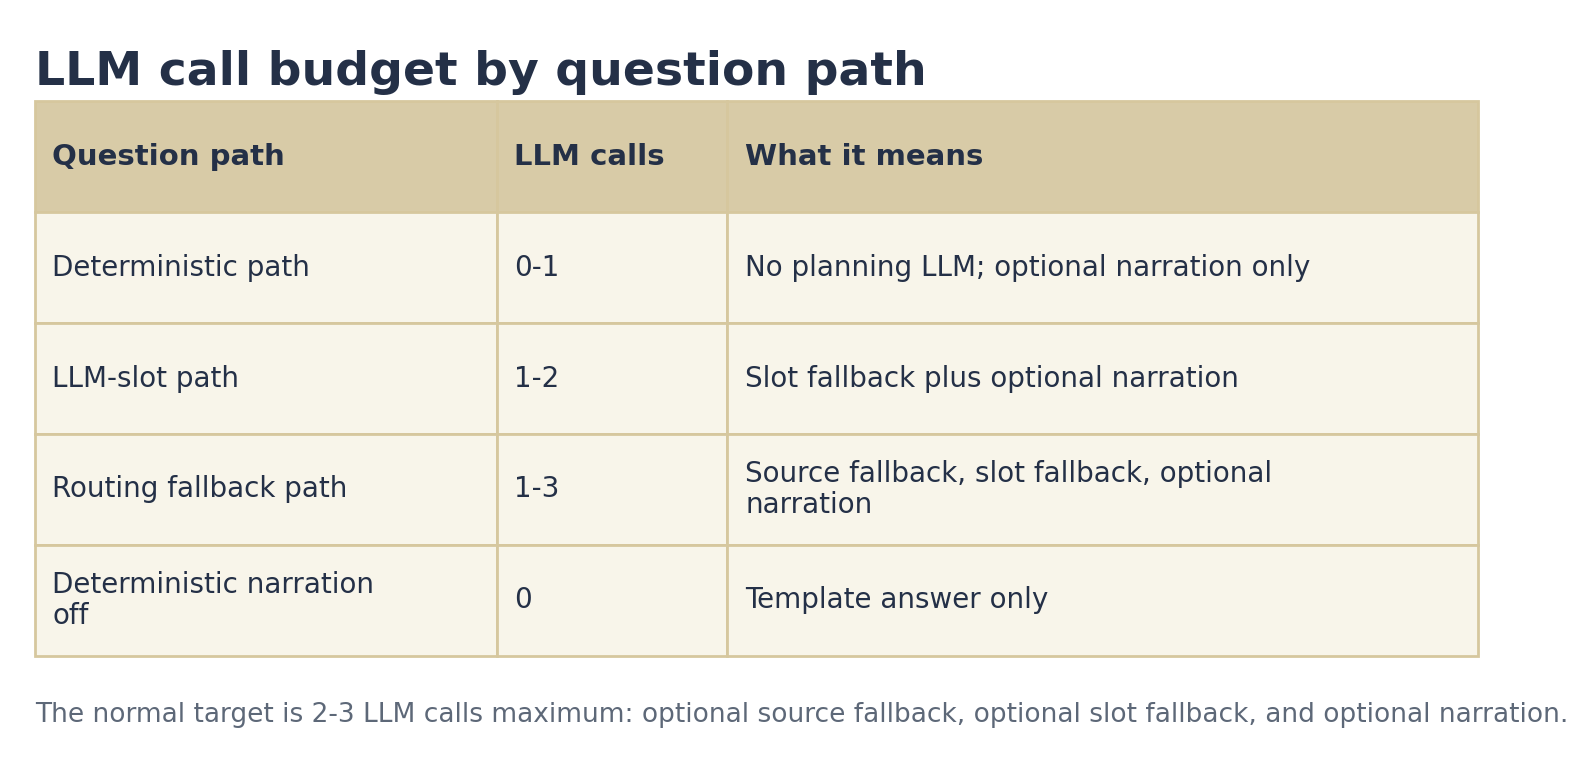

Stage summary:
         stage    avg_ms  avg_sec
Source routing 2405.1375 2.405137
      Planning 2150.3750 2.150375
     Execution   56.8750 0.056875
     Narration 4341.5000 4.341500

Saved bar chart to: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\average_runtime_by_pipeline_stage.png
Saved table to: C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant\outputs\llm_call_budget_table.png


In [14]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import textwrap

ROOT = Path(r"C:\Users\S_YZH\OneDrive - Televic Group NV\Desktop\HistoryAssistant")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

timing_rows = [
    {
        "question": "how many urgent calls in February 2024",
        "path": "deterministic + narration",
        "source_routing_ms": 1030.6,
        "classification_ms": 2218,
        "planning_ms": 297,
        "execution_ms": 110,
        "narration_ms": 8281,
        "llm_calls": 1,
    },
    {
        "question": "urgent calls by ward in February 2024",
        "path": "deterministic + narration",
        "source_routing_ms": 0.7,
        "classification_ms": 62,
        "planning_ms": 219,
        "execution_ms": 31,
        "narration_ms": 3516,
        "llm_calls": 1,
    },
    {
        "question": "who was present on 2024-02-01",
        "path": "source fallback + narration",
        "source_routing_ms": 7437.0,
        "classification_ms": 1516,
        "planning_ms": 218,
        "execution_ms": 47,
        "narration_ms": 3563,
        "llm_calls": 2,
    },
    {
        "question": "last known location of staff <hash>",
        "path": "source fallback + narration",
        "source_routing_ms": 5326.1,
        "classification_ms": 3453,
        "planning_ms": 515,
        "execution_ms": 94,
        "narration_ms": 2438,
        "llm_calls": 2,
    },
    {
        "question": "who moved most last week",
        "path": "source fallback + planning fallback + narration",
        "source_routing_ms": 5444.1,
        "classification_ms": 6515,
        "planning_ms": 7625,
        "execution_ms": 63,
        "narration_ms": 5312,
        "llm_calls": 2,
    },
    {
        "question": "maximum activation time by ward in February 2024",
        "path": "planning fallback / unresolved",
        "source_routing_ms": 0.7,
        "classification_ms": 63,
        "planning_ms": 7594,
        "execution_ms": 0,
        "narration_ms": 0,
        "llm_calls": 1,
    },
    {
        "question": "show me calls from ward 2V ZONE 2A in February 2024",
        "path": "deterministic + narration",
        "source_routing_ms": 0.9,
        "classification_ms": 93,
        "planning_ms": 344,
        "execution_ms": 16,
        "narration_ms": 4200,
        "llm_calls": 1,
    },
    {
        "question": "average response time by ward in February 2024",
        "path": "deterministic + narration",
        "source_routing_ms": 1.0,
        "classification_ms": 93,
        "planning_ms": 391,
        "execution_ms": 94,
        "narration_ms": 7422,
        "llm_calls": 1,
    },
]

df = pd.DataFrame(timing_rows)

stage_cols = {
    "Source routing": "source_routing_ms",
    "Planning": "planning_ms",
    "Execution": "execution_ms",
    "Narration": "narration_ms",
}

stage_summary = pd.DataFrame({
    "stage": list(stage_cols.keys()),
    "avg_ms": [df[col].mean() for col in stage_cols.values()],
})
stage_summary["avg_sec"] = stage_summary["avg_ms"] / 1000

llm_table = pd.DataFrame([
    {
        "Question path": "Deterministic path",
        "LLM calls": "0-1",
        "What it means": "No planning LLM; optional narration only",
    },
    {
        "Question path": "LLM-slot path",
        "LLM calls": "1-2",
        "What it means": "Slot fallback plus optional narration",
    },
    {
        "Question path": "Routing fallback path",
        "LLM calls": "1-3",
        "What it means": "Source fallback, slot fallback, optional narration",
    },
    {
        "Question path": "Deterministic narration off",
        "LLM calls": "0",
        "What it means": "Template answer only",
    },
])

TEXT = "#243047"
GRID = "#D6C79E"
COLORS = ["#9FCFCA", "#AEBF9F", "#CDBF9D", "#E3D8B6"]

plt.rcParams["font.family"] = "DejaVu Sans"


# -----------------------------
# 1. Separate bar chart image
# -----------------------------
fig, ax = plt.subplots(figsize=(8.5, 5.0), dpi=200)

bars = ax.bar(
    stage_summary["stage"],
    stage_summary["avg_sec"],
    color=COLORS,
    width=0.62,
)

ax.set_title(
    "Average runtime by pipeline stage",
    fontsize=17,
    weight="bold",
    color=TEXT,
    pad=16,
)
ax.set_ylabel("Seconds", fontsize=11, color=TEXT)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:.1f}s"))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
ax.set_axisbelow(True)
ax.tick_params(axis="both", labelsize=10, colors=TEXT)

for bar, sec in zip(bars, stage_summary["avg_sec"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        sec,
        f"{sec:.2f}s",
        ha="center",
        va="bottom",
        fontsize=10,
        weight="bold",
        color=TEXT,
    )

ax.text(
    0.5,
    -0.16,
    "Measured from representative debug timings. Execution is fast; narration and fallback steps dominate latency.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9.5,
    color="#5D6878",
)

plt.tight_layout()

bar_out = OUT / "average_runtime_by_pipeline_stage.png"
plt.savefig(bar_out, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()


# -----------------------------
# 2. Separate LLM table image
# -----------------------------
fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=200)
ax.axis("off")

ax.text(
    0.01,
    0.96,
    "LLM call budget by question path",
    transform=ax.transAxes,
    fontsize=17,
    weight="bold",
    color=TEXT,
    va="top",
)

columns = ["Question path", "LLM calls", "What it means"]
col_widths = [0.32, 0.16, 0.52]

HEADER_BG = "#D8CBA7"
ROW_BG = "#F8F5EA"
EDGE = "#D6C79E"

x0 = 0.01
table_w = 0.98
header_y = 0.74
row_h = 0.15

def draw_cell(x, y, w, h, text, bg, bold=False, fontsize=10.5):
    rect = plt.Rectangle(
        (x, y),
        w,
        h,
        transform=ax.transAxes,
        facecolor=bg,
        edgecolor=EDGE,
        linewidth=1.0,
    )
    ax.add_patch(rect)

    wrap_chars = max(8, int(w * 85))
    wrapped = "\n".join(textwrap.wrap(str(text), width=wrap_chars))

    ax.text(
        x + 0.012,
        y + h / 2,
        wrapped,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=fontsize,
        weight="bold" if bold else "normal",
        color=TEXT,
        linespacing=1.15,
    )

# Header
x = x0
for col, cw in zip(columns, col_widths):
    draw_cell(
        x,
        header_y,
        cw * table_w,
        row_h,
        col,
        HEADER_BG,
        bold=True,
        fontsize=10.5,
    )
    x += cw * table_w

# Rows
# Rows
for i, row in llm_table.iterrows():
    y = header_y - (i + 1) * row_h
    x = x0
    for col, cw in zip(columns, col_widths):
        draw_cell(
            x,
            y,
            cw * table_w,
            row_h,          # <- missing height
            row[col],
            ROW_BG,
            fontsize=10,
        )
        x += cw * table_w

ax.text(
    0.01,
    0.05,
    "The normal target is 2-3 LLM calls maximum: optional source fallback, optional slot fallback, and optional narration.",
    transform=ax.transAxes,
    fontsize=9.5,
    color="#5D6878",
)

table_out = OUT / "llm_call_budget_table.png"
plt.savefig(table_out, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

print("Stage summary:")
print(stage_summary.to_string(index=False))
print(f"\nSaved bar chart to: {bar_out}")
print(f"Saved table to: {table_out}")